------------------------------------------------
['air', 'lxe', 'lxe2', 'cf4', 'green', 'red']
style object members: 	 ['col', 'ls', 'name', 'printMembers']


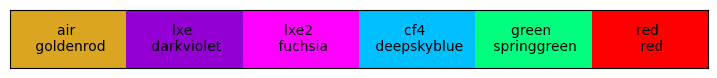

In [4]:
import matplotlib.pyplot as plt
import copy
import numpy as np
import pandas as pd

import json

import sys
sys.path.append('../')
from DAAPS_TOOLKIT.GenPaths import *

import PDEModel.MathEquations as ME
# from PDEModel.OpticsDataLoader import *
import PDEModel.PDEStyle as MS
import PDEModel.PhotonInfo as PI # this calls DataLoader when defining init
import PNJunction as PNJ

import FittingFunctions as FFs

# rad2deg = 180/np.pi

MS.ShowMyStyles() # for colors
ms = MS.MyStyleSet() # object to use like
ms.SetMPLcolors() # turn off with "off" option

## should enforce the 'table' here. use 1-R for oblique angles, and then use real_theta3 for oblique angles and wlen < 155nm

# only doing down to 160 nm
# for wlens below that, should use T equation but with real theta_3 (approximation)

In [7]:
# dhFranta = OpticsData(siDataPath=os.path.join(OPTICS_DATA_PATH, "Franta_data", "Franta-150K.txt"))
dhFranta = None
# fixedPars_Boring = {"quantum": False, "smoothSigma": 9/2.335, "dh":dhFranta, "window":True}

with open("input_systematics.json", 'r') as file:
    json_systematic = json.load(file)

saveFlag = False
configName = "_defaultData_globalPar_160k"
window = False
shadowingH = None ## FBK

### HPK specifics ###
# FF1 = json_systematic["HPK_VUV4"]["input_systematics"]["FF"]
# tOxide_values = json_systematic["HPK_VUV4"]["input_systematics"]["tOxide"]
# ttGood = tOxide_values[0] # good thickness in nm
# vOffset = json_systematic["HPK_VUV4"]["Voffset"][1]
# pnParameters = json_systematic["HPK_VUV4"]["fit_parameters"]
# pnParameters = {key: pnParameters[key][0] for key in pnParameters}

## HPK
window = True
FF1 = 0.6 ## HPK
ttGood = 17.2 #nm
# shadowingH = 2.5/50 ## HPK

devName = "HPK-VUV4_noWindow_17nmOxide" + configName
pnParameters = {"dp_star": 1.02, "Xpn": 2.3e3, "dw_star":13.6e3, "Ve":1.79, "Vh":16.6}
mediumProduction = "lxe"

### comment out this section to do HPK ###
######### FBK
# window = False
# FF1 = 0.8
# ttGood = 1360
# devName = "FBK-LF_1360nmOxide" + configName
# pnParameters = {"dp_star": 0.96, "Xpn": 510, "dw_star":8.33e3, "Ve":1.83, "Vh":18.77}
# ## comment out these 5 lines if using HPK_VUV4

#########
fixedPars_parametrized = {"Ae":1.0, "Ah":1.0}
fixedPars_physics = {"FF": FF1, "Temperature": 160, "tOxide":ttGood}

### keep this
opticsName = "optics_" + devName + ".csv"
internalName = "internalPDE_" + devName + ".csv"
onlyWname = "absorptionOnly_" + devName + ".csv"

# Define the range of angles and wavelengths
wlenRange = np.arange(155, 1100, 2.5)
angles = np.arange(0, 90, 2.5)

# print(pnParameters)
# # print(fixedPars_Boring)
# print(fixedPars_physics)
# print(fixedPars_parametrized)

Columns in the data: ['run', 'wlen', 'angle', 'yNorm', 'yNormErr', 'voltage']
Run vis6V, Wlen 600.0 nm: std (angles -20..30) = 0.011469
Run vis6V, Wlen 640.0 nm: std (angles -20..30) = 0.010439
Run vis6V, Wlen 730.0 nm: std (angles -20..30) = 0.009952
Run vis6V, Wlen 780.0 nm: std (angles -20..30) = 0.022608
Run visJune, Wlen 599.981 nm: std (angles -20..30) = 0.007513
Run visJune, Wlen 639.887 nm: std (angles -20..30) = 0.006464
Run visJune, Wlen 659.927 nm: std (angles -20..30) = 0.013587
Run visJune, Wlen 729.997 nm: std (angles -20..30) = 0.017757
Run visJune, Wlen 779.872 nm: std (angles -20..30) = 0.009652
Run visJune, Wlen 829.983 nm: std (angles -20..30) = 0.011826
Run midMarch, Wlen 589.945 nm: std (angles -20..30) = 0.017686
Run midMarch, Wlen 709.952 nm: std (angles -20..30) = 0.012785


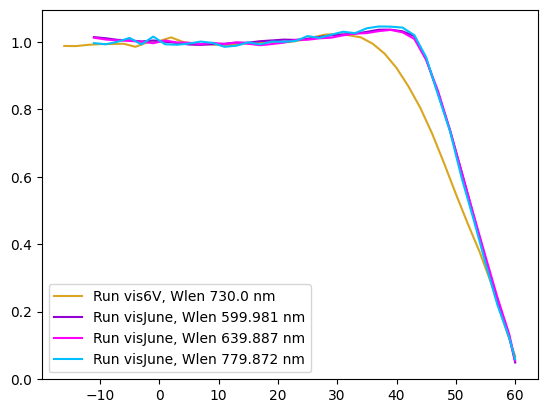

In [29]:
# load the compiled angular data and plot rows with wlen > 500
csv_path = "/Users/austindestcroix/Desktop/school_holders/projects/vera/daaps/veraData/compiled_angular_data_HPKVUV4.csv"

df = pd.read_csv(csv_path)

# ensure wlen is numeric
df['wlen'] = pd.to_numeric(df['wlen'], errors='coerce')
df = df.dropna(subset=['wlen'])

names = df.columns.tolist()
print("Columns in the data:", names)

# find unique wavelengths > 500
wlens = sorted(df['wlen'].unique())

# filter for wavelengths > 500 nm
df_gt500 = df[df['wlen'] > 500].copy()

# unique (run, wlen) pairs
unique_pairs = df_gt500[['run', 'wlen']].drop_duplicates().reset_index(drop=True)
unique_pairs_list = list(unique_pairs.itertuples(index=False, name=None))

std_vals = []
class dataTemp:
  pass
# build a dict mapping (run, wlen) -> angle, yNorm (and error / df if needed)
datasets = []
for runID, w in unique_pairs_list:
  sub = df_gt500[(df_gt500['run'] == runID) & (df_gt500['wlen'] == w)].sort_values('angle')
  x = sub['angle'].values
  y = sub['yNorm'].values
  yErr = sub['yNormErr'].values
  
  
  mask = (x >= -20) & (x <= 30)
  std_val = np.std(y[mask]) if np.any(mask) else np.nan
  std_vals.append(std_val)
  print(f"Run {runID}, Wlen {w} nm: std (angles -20..30) = {std_val:.6f}")

  if std_val < 0.01:
    plt.plot(x, y, label=f"Run {runID}, Wlen {w} nm")
    
    dat = dataTemp()
    dat.angle = x
    dat.yNorm = y
    dat.yNormErr = yErr
    dat.wlen = w
    dat.run = runID
    datasets.append(dat)
  
plt.legend()
# plt.hist(std_vals, bins=20, edgecolor='black')


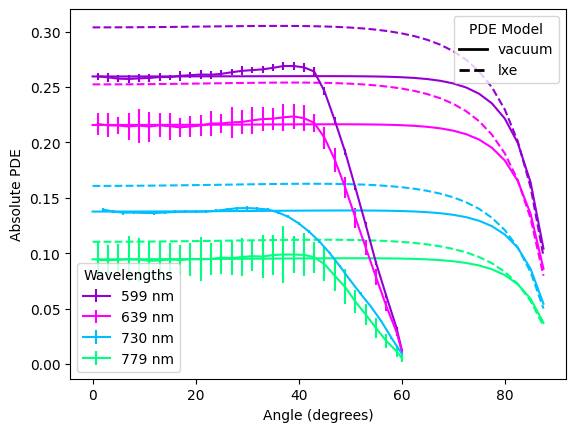

In [41]:
from matplotlib.lines import Line2D

# sort datasets in-place by wavelength
datasets.sort(key=lambda d: float(d.wlen))
ms.ResetColorCycle()
ms.GetNextColor()

for dat in datasets:
  
  wlen = dat.wlen
  
  ## model
  pde1 = FFs.PDE_allArgs_wlen_parametrized_forMedium(wlen = np.array([wlen]), voltage = 4, theta1 = angles, medium = "vacuum", **fixedPars_parametrized, **fixedPars_physics, **pnParameters)
  pdeAtZero = np.average(pde1[angles <= 5])
  
  pdeXe = FFs.PDE_allArgs_wlen_parametrized_forMedium(wlen = np.array([wlen]), voltage = 4, theta1 = angles, medium = "lxe", **fixedPars_parametrized, **fixedPars_physics, **pnParameters)
  # pdeAr = FFs.PDE_allArgs_wlen_parametrized_forMedium(wlen = np.array([wlen]), voltage = 4, theta1 = angles, medium = "lAr", **fixedPars_parametrized, **fixedPars_physics, **pnParameters)
  
  ## data
  dataDown = dat.yNorm * pdeAtZero

  plt.plot(angles, pde1, color = ms.GetNextColor())
  plt.plot(angles, pdeXe, linestyle = "--", color = ms.GetNextColor(1))
  plt.errorbar(dat.angle[dat.angle > 0], dataDown[dat.angle > 0], yerr=dat.yNormErr[dat.angle > 0], color = ms.GetNextColor(1), label = f"{int(wlen)} nm")

plt.legend(title="Wavelengths")
plt.xlabel("Angle (degrees)")
plt.ylabel("Absolute PDE")

ax = plt.gca()
first_leg = ax.get_legend()  # preserve existing wavelength legend

handles = [
  Line2D([0], [0], color='k', ls='-', lw=2),
  Line2D([0], [0], color='k', ls='--', lw=2)
]
labels = ['vacuum', 'lxe']

ax.legend(handles, labels, title='PDE Model', loc='upper right')
if first_leg is not None:
  ax.add_artist(first_leg)
plt.show()